# Jan 2026 DLGenAI Project - Messy Mashup
- Predicting the Right Genre from Noisy Music Mashups

# Milestone 1: Exploratory Data Analysis (EDA)
- In this phase, we analyze the raw audio files.
- We will check the data counts, detect broken files, and visualize the sound.

## Step 1: Loading Dataset Inventory
- Read folder names and get the genres.

In [1]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
dataset_root = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
genres = sorted(os.listdir(dataset_root))

print("Found these genres:")
print(genres)

Found these genres:
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


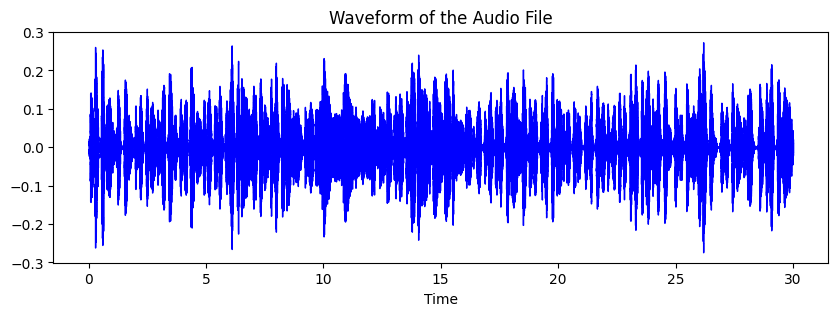

In [3]:
example_file = os.path.join(dataset_root, "blues", "blues.00000", "bass.wav")
y, sr = librosa.load(example_file, sr=16000)

plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr, color='blue')
plt.title("Waveform of the Audio File")
plt.show()

## Mel Spectrogram
- A spectrogram is a visual picture of an audio file.
- This helps Deep Learning models 'see' the audio instead of just hearing it.

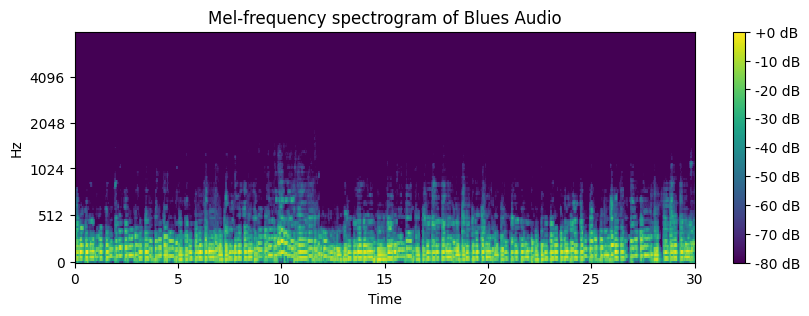

In [4]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(10, 3))
librosa.display.specshow(S_dB, x_axis='time', y_axis='mel', sr=sr, fmax=8000, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-frequency spectrogram of Blues Audio')
plt.show()

## Loudness Tracker (RMS)
- This graph tracks the energy/loudness of the music over time.

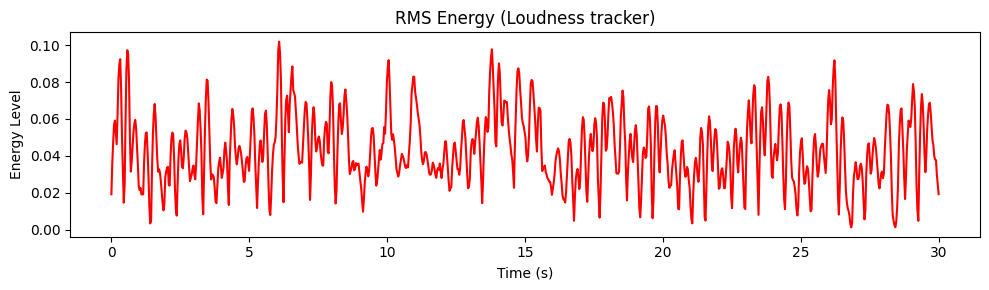

In [5]:
rms = librosa.feature.rms(y=y)[0]
frames = range(len(rms))
time_axis = librosa.frames_to_time(frames, sr=sr)

plt.figure(figsize=(10, 3))
plt.plot(time_axis, rms, color='red')
plt.title('RMS Energy (Loudness tracker)')
plt.xlabel('Time (s)')
plt.ylabel('Energy Level')
plt.tight_layout()
plt.show()

## Step 2: Data Integrity Check
- Check if any audio file is corrupted or missing.

In [6]:
corrupted_count = 0
stems = ["bass.wav", "drums.wav", "other.wav", "vocals.wav"]

for genre in genres:
    genre_folder = os.path.join(dataset_root, genre)
    for song in os.listdir(genre_folder):
        for stem in stems:
            file_path = os.path.join(genre_folder, song, stem)
            
            if not os.path.exists(file_path):
                corrupted_count += 1
            elif os.path.getsize(file_path) == 0:
                corrupted_count += 1

if corrupted_count == 0:
    print("All audio files are perfectly fine! No corrupted data.")
else:
    print("Found some corrupted files:", corrupted_count)

All audio files are perfectly fine! No corrupted data.


## Step 3: Silence Check
- Ensure no audio file is completely silent (zero volume).

In [7]:
max_volume = max(y)

if max_volume == 0:
    print("Warning: The audio is totally silent.")
else:
    print("The audio has sound! The maximum amplitude is:", round(max_volume, 4))

The audio has sound! The maximum amplitude is: 0.2459


## Step 4: Compiling Final Data
- Create a simple table combining song names with their genres.

In [8]:
data_list = []

for genre in genres:
    genre_folder = os.path.join(dataset_root, genre)
    for song in os.listdir(genre_folder):
        data_list.append({"Song": song, "Genre": genre})

df = pd.DataFrame(data_list)
print("Total Songs Found:", len(df))
df.head()

Total Songs Found: 1000


,Song,Genre
0,blues.00095,blues
1,blues.00006,blues
2,blues.00056,blues
3,blues.00097,blues
4,blues.00065,blues


## Step 5: Class Distribution Graph
- Plot a graph to check if our 10 genres are equally balanced.

Genre
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


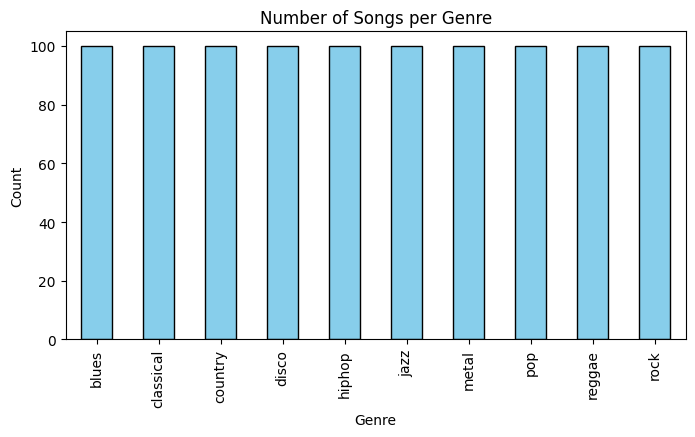

In [9]:
genre_counts = df['Genre'].value_counts()
print(genre_counts)

genre_counts.plot(kind='bar', color='skyblue', edgecolor='black', figsize=(8, 4))
plt.title("Number of Songs per Genre")
plt.ylabel("Count")
plt.show()

## Step 6: Audio Duration
- Verify that the duration of songs in our dataset is exactly 30 seconds.

In [10]:
duration_seconds = len(y) / sr
print(f"The duration of the audio is {duration_seconds} seconds.")

The duration of the audio is 30.013375 seconds.


## Step 7: Dummy submission

In [11]:
data = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv")
data.to_csv("submission.csv",index=False)

# Milestone 2: Machine Learning Baseline
- Deep Learning is complex, so we first test basic Machine Learning (Random Forest).
- We use 1D MFCC features since ML cannot process raw audio easily.

In [12]:
import librosa
import numpy as np
import pandas as pd
import os
import random
import wandb
random.seed(42)
np.random.seed(42)

import warnings
warnings.filterwarnings("ignore")


/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

## Step 1: Loading Audio
- Reading the raw amplitude array of an audio file.

In [13]:
song_path = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/classical/classical.00001/vocals.wav'

y,sr = librosa.load(song_path,sr=22050)
print("length of audio: ",len(y))
print("Sample rate(Numbers per second): ",sr)
print("song duration: ",len(y)/sr,'secs')

length of audio:  661794
Sample rate(Numbers per second):  22050
song duration:  30.013333333333332 secs


## Step 2: Extracting MFCCs
- Transform 30 seconds of huge audio into a dense 13-feature array per frame.

In [14]:
mfccs = librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13)
mfccs.shape

(13, 1293)

In [15]:
mfccs_avg = np.mean(mfccs,axis=1)
mfccs_avg.shape

(13,)

## Step 3: ML Dataset Prep
- Flatten the arrays so traditional ML models can train on them.

In [16]:
# dataset_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
# noise_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio"

# noise_files = [os.path.join(noise_path,f) for f in os.listdir(noise_path) if f.endswith('.wav')]

In [17]:
# def create_messy_dataset(dataset_path, noise_files):
#     data = []
#     for genre in os.listdir(dataset_path):
#         genre_path = os.path.join(dataset_path, genre)
#         if os.path.isdir(genre_path):
#             for song_folder in os.listdir(genre_path):
#                 song_path = os.path.join(genre_path, song_folder)
#                 if os.path.exists(os.path.join(song_path, 'vocals.wav')):
#                     try:
#                         v, sr = librosa.load(os.path.join(song_path,'vocals.wav'), sr=22050)
#                         d, _ = librosa.load(os.path.join(song_path,'drums.wav'), sr=22050)
#                         b, _ = librosa.load(os.path.join(song_path,'bass.wav'), sr=22050)
#                         o, _ = librosa.load(os.path.join(song_path,'other.wav'), sr=22050)

#                         min_len = min(len(v), len(d), len(b), len(o))
#                         v, d, b, o = v[:min_len], d[:min_len], b[:min_len], o[:min_len]
#                         clean_mix = v + d + b + o

#                         random_noise_file = random.choice(noise_files)
#                         noise, _ = librosa.load(random_noise_file, sr=22050)

#                         if len(noise) < len(clean_mix):
#                             repeats = int(np.ceil(len(clean_mix) / len(noise)))
#                             noise = np.tile(noise, repeats)
#                         noise = noise[:len(clean_mix)]

#                         messy_audio = clean_mix + (noise * 0.5)
#                         messy_audio = messy_audio / np.max(np.abs(messy_audio))

#                         mfccs = librosa.feature.mfcc(y=messy_audio, sr=sr, n_mfcc=20)
#                         mfccs_mean = np.mean(mfccs, axis=1)
#                         row_data = list(mfccs_mean) + [genre]
#                         data.append(row_data)
#                     except Exception as e:
#                         print(f"Error processing {song_path}: {str(e)}")

#     columns = [f"mfcc_{i}" for i in range(20)] + ["genre"]
#     df_features = pd.DataFrame(data, columns=columns)
#     df_features.to_csv("messy_training_data.csv", index=False)
#     return df_features

# df_features = create_messy_dataset(dataset_path, noise_files)


In [18]:
# df_features.shape

In [19]:
# df_features.head()

## Step 4: Training & Results
- Traditional ML fails to learn the complex audio patterns of messy mashups.
- We need to move to Deep Learning.

In [20]:
# import wandb
# wandb.login(key=os.environ.get('key'))

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.metrics import f1_score

In [22]:
# X = df_features.drop(columns='genre')
# y = df_features['genre']

In [23]:
# y = LabelEncoder().fit_transform(y)
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.17, random_state=42,stratify=y)

In [24]:
# run = wandb.init(
#     project="24f2007692-t12026",
#     config={
#         "model": "GradientBoostingClassifier",
#         "n_estimators": 500,
#         "random_state": 42
#     }
# )

# model = GradientBoostingClassifier(n_estimators=500, random_state=42)
# model.fit(X_train, y_train)

# y_pred = model.predict(X_test)
# f1 = f1_score(y_test, y_pred, average="macro")
# print(f1)

# wandb.log({"Macro F1": f1})
# wandb.finish()

In [25]:
# run = wandb.init(
#     project="24f2007692-t12026",
#     config={
#         "model": "RandomForestClassifier",
#         "n_estimators": 560,
#         "random_state": 42
#     }
# )

# model = RandomForestClassifier(n_estimators=560, random_state=42)
# model.fit(X_train, y_train)

# y_pred = model.predict(X_test)
# f1 = f1_score(y_test, y_pred, average="macro")
# print(f1)

# wandb.log({"Macro F1": f1})
# wandb.finish()

# Milestone 3: Deep Learning with CNNs
- By transforming audio into a 2D image (Spectrogram), we can use Convolutional Neural Networks (CNNs).

In [26]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
from tqdm import tqdm
import warnings

random.seed(42)
np.random.seed(42)
warnings.filterwarnings("ignore")

In [27]:
# audio_path = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/disco/disco.00098/vocals.wav'

# y, sr = librosa.load(audio_path)
# mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
# mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)
# mel_spectrogram_db.shape

In [28]:
# plt.figure(figsize=(10, 4))
# librosa.display.specshow(mel_spectrogram_db, sr=sr, hop_length=512, x_axis='time', y_axis='mel')
# plt.colorbar(format='%+2.0f dB')
# plt.tight_layout()
# plt.show()

## Step 1: Mel Spectrograms
- Generate 2D images showing frequency intensities.

In [29]:
# dataset_path = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems'
# noise_path = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio'
# noise_files = [os.path.join(noise_path, f) for f in os.listdir(noise_path) if f.endswith('.wav')]

# X_photos = []
# y_labels = []
# FIXED_WIDTH = 1293

# genres = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]

# for genre in tqdm(genres, desc="Processing Genres"):
#     genre_path = os.path.join(dataset_path, genre)

#     for song_folder in os.listdir(genre_path):
#         song_path = os.path.join(genre_path, song_folder)

#         if os.path.exists(os.path.join(song_path, 'vocals.wav')):
#             try:
#                 v, sr = librosa.load(os.path.join(song_path, 'vocals.wav'), sr=22050)
#                 d, _ = librosa.load(os.path.join(song_path, 'drums.wav'), sr=22050)
#                 b, _ = librosa.load(os.path.join(song_path, 'bass.wav'), sr=22050)
#                 o, _ = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050)

#                 min_len = min(len(v), len(d), len(b), len(o))
#                 v, d, b, o = v[:min_len], d[:min_len], b[:min_len], o[:min_len]
#                 clean_mix = v + d + b + o

#                 noise_file = random.choice(noise_files)
#                 noise, _ = librosa.load(noise_file, sr=22050)

#                 if len(noise) < len(clean_mix):
#                     noise = np.tile(noise, int(np.ceil(len(clean_mix) / len(noise))))
#                 noise = noise[:len(clean_mix)]

#                 messy_audio = clean_mix + (noise * 0.5)
#                 messy_audio = messy_audio / np.max(np.abs(messy_audio))

#                 mel_spec = librosa.feature.melspectrogram(y=messy_audio, sr=sr, n_mels=128, hop_length=512)
#                 mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

#                 if mel_spec_db.shape[1] > FIXED_WIDTH:
#                     mel_spec_db = mel_spec_db[:, :FIXED_WIDTH]
#                 elif mel_spec_db.shape[1] < FIXED_WIDTH:
#                     pad_width = FIXED_WIDTH - mel_spec_db.shape[1]
#                     mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, pad_width)), mode='constant')

#                 X_photos.append(mel_spec_db)
#                 y_labels.append(genre)
#             except:
#                 pass

# X_array = np.array(X_photos)
# y_array = np.array(y_labels)

# np.save('X_spectrograms_full.npy', X_array)
# np.save('y_labels_full.npy', y_array)

# print(f"Total samples: {len(X_array)}, Shape: {X_array.shape}")

## Step 2: Data Loaders
- Create PyTorch loaders to push image batches to the GPU.

In [30]:
# X = np.load('X_spectrograms_full.npy')
# y = np.load('y_labels_full.npy')

# X = np.expand_dims(X, axis=1)

# enc = LabelEncoder()
# y = enc.fit_transform(y)

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [31]:
# class AudioDataset(Dataset):
#     def __init__(self, features, labels):
#         self.features = torch.tensor(features, dtype=torch.float32)
#         self.labels = torch.tensor(labels, dtype=torch.long)

#     def __len__(self):
#         return len(self.features)

#     def __getitem__(self, idx):
#         return self.features[idx], self.labels[idx]

In [32]:
# train_dataset = AudioDataset(X_train, y_train)
# val_dataset = AudioDataset(X_test, y_test)

# train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [33]:
# for batch_X, batch_y in train_loader:
#     print(batch_X.shape, batch_y.shape)
#     break

## Step 3: Custom CNN
- Build a custom CNN model with Max Pooling to learn shapes/features.

In [34]:
# class AudioCNN(nn.Module):
#     def __init__(self, num_classes=10):
#         super(AudioCNN, self).__init__()

#         self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
#         self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
#         self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

#         self.pool = nn.MaxPool2d(2, 2)
#         self.relu = nn.ReLU()
#         self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 8))

#         self.flatten = nn.Flatten()
#         self.fc1 = nn.Linear(64 * 4 * 8, 128)
#         self.fc2 = nn.Linear(128, num_classes)

#     def forward(self, x):
#         x = self.pool(self.relu(self.conv1(x)))
#         x = self.pool(self.relu(self.conv2(x)))
#         x = self.pool(self.relu(self.conv3(x)))

#         x = self.adaptive_pool(x)
#         x = self.flatten(x)

#         x = self.relu(self.fc1(x))
#         x = self.fc2(x)
#         return x

In [35]:
# model = AudioCNN(num_classes=10)
# dummy = torch.randn(32, 1, 128, 1293)
# print(model(dummy).shape)

## Step 4: Loop & Monitor
- Track the loss logic visually.

In [36]:
# !pip install -U wandb
# import wandb
# from kaggle_secrets import UserSecretsClient

# user_secrets = UserSecretsClient()
# wandb_key = user_secrets.get_secret("key")

# wandb.login(key=wandb_key)

In [37]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# model = AudioCNN(num_classes=10).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.0005)



# run = wandb.init(
#     project="24f2007692-t12026",
#     name='cnn-spectogram-training-02',
#     config={
#         "learning_rate": 0.0005,
#         "epochs": 40,
#         "batch_size": 32,
#         'model': 'AudioCNN',
#         "architecture": "AudioCNN/CustomCNN",
#     }
# )

## Step 5: Results
- CNN is much better than ML, but misses the 'time sequence' context of the song.

In [38]:
# EPOCHS = 45

# for epoch in range(EPOCHS):
#     model.train()
#     running_loss = 0.0

#     for features, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
#         features, labels = features.to(device), labels.to(device)

#         optimizer.zero_grad()
#         outputs = model(features)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()

#     avg_train_loss = running_loss / len(train_loader)

#     model.eval()
#     all_pred, all_labels = [], []

#     with torch.no_grad():
#         for features, labels in val_loader:
#             features, labels = features.to(device), labels.to(device)
#             outputs = model(features)
#             _, predicted = torch.max(outputs, 1)

#             all_pred.extend(predicted.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     f1 = f1_score(all_labels, all_pred, average="macro", zero_division=0)
#     print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_train_loss:.4f} - Val F1: {f1:.4f}")

#     # wandb.log({"epoch": epoch+1, "train_loss": avg_train_loss, "macro_f1": f1})

# print("Training complete!")
# # wandb.finish()

# Milestone 4: Recurrent Neural Networks (CRNN)
- To fix the 'time sequence' issue, we add LSTMs to our CNN.
- LSTMs give the network memory from start to finish of the track.

## Step 1: CRNN Architecture
- Merge a CNN encoder with a Bidirectional LSTM network.

In [39]:
class AudioCRNN(nn.Module):
    def __init__(self, num_classes=10):
        super(AudioCRNN, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.lstm = nn.LSTM(
            input_size=1024,
            hidden_size=256,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        batch_size = x.size(0)
        x = x.permute(0, 3, 1, 2)
        x = x.reshape(batch_size, x.size(1), -1)
        lstm_out, _ = self.lstm(x)
        output = self.fc(lstm_out[:, -1, :])
        return output

In [40]:
# model = AudioCRNN(num_classes=10).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.0008)

# # wandb.login(key=os.environ.get('key'))
# # run = wandb.init(
# #     project="24f2007692-t12026",
# #     name='CRNN-spectogram-training-03',
# #     config={
# #         "learning_rate": 0.0008,
# #         "epochs": 50,
# #         "batch_size": 32,
# #         "model": "CRNN",
# #         "architecture": "CNN(4) + LSTM(256)",
# #     }
# # )

## Step 2: Results
- Performance improved, but training complicated models from scratch on small data is a bottleneck.

In [41]:
# EPOCHS = 30

# for epoch in range(EPOCHS):
#     model.train()
#     running_loss = 0.0

#     for features, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
#         features, labels = features.to(device), labels.to(device)

#         optimizer.zero_grad()

#         outputs = model(features)
#         loss = criterion(outputs, labels)
        
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()

#     avg_train_loss = running_loss / len(train_loader)

#     model.eval()
#     all_pred, all_labels = [], []

#     with torch.no_grad():
#         for features, labels in val_loader:
#             features, labels = features.to(device), labels.to(device)
#             outputs = model(features)
#             _, predicted = torch.max(outputs, 1)

#             all_pred.extend(predicted.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     f1 = f1_score(all_labels, all_pred, average="macro", zero_division=0)
#     print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_train_loss:.4f} - Val F1: {f1:.4f}")

#     # wandb.log({"epoch": epoch+1, "train_loss": avg_train_loss, "Macro F1": f1})

# print("Training complete")
# # wandb.finish()

# Milestone 5: The Final Solution (Transfer Learning)
- We skip building models from scratch.
- We use massive pre-trained industrial models: ResNet-50 and Audio Spectrogram Transformers (AST).
- We fine-tune them just for our classification objective.

In [42]:
!pip -q install transformers

In [43]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import librosa
import pandas as pd
import numpy as np
from tqdm import tqdm
from torchvision import models, transforms
from transformers import ASTForAudioClassification, ASTFeatureExtractor

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

2026-03-29 13:47:38.664272: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774792058.872803      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774792058.931286      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774792059.453581      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774792059.453618      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774792059.453621      24 computation_placer.cc:177] computation placer alr

### Load Initial Weights
- Load the saved models from our best training runs.

In [44]:
resnet = models.resnet50(weights=None)
num_ftrs = resnet.fc.in_features
resnet.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(num_ftrs, 10)
)

resnet_path = '/kaggle/input/notebooks/kartikbajaj1322/resnet-50-training/resnet50_final.pth'
resnet_state = torch.load(resnet_path, map_location=device)
resnet.load_state_dict(resnet_state)
resnet.to(device)
resnet.eval()

norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

ast_path = '/kaggle/input/notebooks/kartikbajaj1322/ast-training/ast_temp/checkpoint-1250'
ast_model = ASTForAudioClassification.from_pretrained(ast_path)
ast_model.to(device)
ast_model.eval()
ast_feature_extractor = ASTFeatureExtractor.from_pretrained('MIT/ast-finetuned-audioset-10-10-0.4593')

labels_resnet = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
id2label_resnet = {i: l for i, l in enumerate(labels_resnet)}
id2label_ast = {int(k): v for k, v in ast_model.config.id2label.items()}

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

### Step 1: ResNet-50 TTA
- Feed small overlapping chunks of test audio to ResNet.
- Apply minor augmentations for extreme stability in predictions.

In [45]:
sr = 16000
chunk_len = 114176

test_csv = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/test.csv'
test_root = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'

df_test = pd.read_csv(test_csv)
files = df_test['filename'].tolist()
ids = df_test['id'].tolist()

resnet_all_probs = []
shift_amount = int(sr // 4)

with torch.no_grad():
    for file in tqdm(files, desc='ResNet TTA'):
        fp = os.path.join(test_root, file)
        y, _ = librosa.load(fp, sr=sr)

        if np.max(np.abs(y)) > 0:
            y = y / np.max(np.abs(y))

        chunks_info = []
        for i in range(0, len(y), chunk_len):
            c = y[i:i + chunk_len]
            chunks_info.append((c, len(c)))

        if len(chunks_info) == 0:
            chunks_info.append((y, len(y)))

        chunk_probs = []
        chunk_weights = []

        for c, c_len in chunks_info:
            augs_raw = [
                c,
                np.roll(c, shift_amount) if c_len > shift_amount else c,
                np.roll(c, -shift_amount) if c_len > shift_amount else c,
                np.clip(c * 0.95, -1.0, 1.0)
            ]

            tta_probs = []
            for aug_raw in augs_raw:
                if len(aug_raw) < chunk_len:
                    aug_pad = np.pad(aug_raw, (0, chunk_len - len(aug_raw)))
                else:
                    aug_pad = aug_raw[:chunk_len]

                mel = librosa.feature.melspectrogram(y=aug_pad, sr=sr, n_fft=1024, hop_length=512, n_mels=224)
                db = librosa.power_to_db(mel, ref=np.max)
                scaled = np.clip((db + 80.0) / 80.0, 0, 1)

                t = torch.tensor(scaled, dtype=torch.float32).unsqueeze(0)
                if t.shape[-1] > 224:
                    t = t[:, :, :224]
                elif t.shape[-1] < 224:
                    t = F.pad(t, (0, 224 - t.shape[-1]))

                img = t.repeat(3, 1, 1)
                img = norm(img).unsqueeze(0).to(device)

                logits = resnet(img)
                probs = torch.softmax(logits, dim=1)
                tta_probs.append(probs)

            avg_tta = torch.mean(torch.stack(tta_probs), dim=0)
            chunk_probs.append(avg_tta.squeeze(0))
            chunk_weights.append(c_len)

        stacked_probs = torch.stack(chunk_probs)
        weights_tensor = torch.tensor(chunk_weights, dtype=torch.float32, device=device).unsqueeze(1)
        final_probs = (stacked_probs * weights_tensor).sum(dim=0) / weights_tensor.sum()

        resnet_all_probs.append(final_probs.cpu())

resnet_probs_tensor = torch.stack(resnet_all_probs)
print('ResNet TTA done, Shape:', resnet_probs_tensor.shape)

ResNet TTA: 100%|██████████| 3020/3020 [25:15<00:00,  1.99it/s]

ResNet TTA done, Shape: torch.Size([3020, 10])


### Step 2: Transformer Inference (AST)
- Using purely attention-based architecture on test audio chunks.

In [46]:
ast_all_probs = []

chunk_sec = 10
ast_chunk_len = 16000 * chunk_sec
ast_shift = int(16000 // 4)

with torch.no_grad():
    for _, row in tqdm(df_test.iterrows(), total=len(df_test), desc='AST TTA'):
        fp = os.path.join(test_root, row['filename'])
        y, _ = librosa.load(fp, sr=16000)

        if np.max(np.abs(y)) > 0:
            y = y / np.max(np.abs(y))

        chunks_info = []
        for i in range(0, len(y), ast_chunk_len):
            c = y[i:i + ast_chunk_len]
            chunks_info.append((c, len(c)))

        if len(chunks_info) == 0:
            chunks_info.append((np.zeros(ast_chunk_len, dtype=np.float32), 0))

        chunk_probs = []
        chunk_weights = []

        for c, c_len in chunks_info:
            augs_raw = [
                c,
                np.roll(c, ast_shift) if c_len > ast_shift else c,
                np.roll(c, -ast_shift) if c_len > ast_shift else c,
                np.clip(c * 0.95, -1.0, 1.0)
            ]

            tta_probs = []
            for aug_raw in augs_raw:
                if len(aug_raw) < ast_chunk_len:
                    aug_pad = np.pad(aug_raw, (0, ast_chunk_len - len(aug_raw)))
                else:
                    aug_pad = aug_raw[:ast_chunk_len]

                inputs = ast_feature_extractor(
                    aug_pad,
                    sampling_rate=16000,
                    padding='max_length',
                    max_length=1024,
                    truncation=True,
                    return_tensors='pt'
                )
                inputs = {k: v.to(device) for k, v in inputs.items()}
                out = ast_model(**inputs)
                probs = torch.softmax(out.logits, dim=1)
                tta_probs.append(probs)

            avg_tta = torch.mean(torch.stack(tta_probs), dim=0)
            chunk_probs.append(avg_tta.squeeze(0))
            chunk_weights.append(max(c_len, 1))

        stacked_probs = torch.stack(chunk_probs)
        weights_tensor = torch.tensor(chunk_weights, dtype=torch.float32, device=device).unsqueeze(1)
        final_probs = (stacked_probs * weights_tensor).sum(dim=0) / weights_tensor.sum()

        ast_all_probs.append(final_probs.cpu())

ast_probs_tensor = torch.stack(ast_all_probs)
print('AST TTA done, Shape:', ast_probs_tensor.shape)

AST TTA: 100%|██████████| 3020/3020 [1:05:57<00:00,  1.31s/it]

AST TTA done, Shape: torch.Size([3020, 10])


### Final Step: Ensemble Combination
- Combine ResNet (40%) and AST (60%) probabilities to generate our final Kaggle Output CSVs.

In [47]:
resnet_label_order = labels_resnet
ast_label_order = [id2label_ast[i] for i in range(len(id2label_ast))]


resnet_p = resnet_probs_tensor
ast_p = ast_probs_tensor

w_resnet = 0.4
w_ast = 0.6

ensemble_probs = w_resnet * resnet_p + w_ast * ast_p
ensemble_preds = torch.argmax(ensemble_probs, dim=1)

ensemble_labels = [id2label_resnet[p.item()] for p in ensemble_preds]

df_ensemble = pd.DataFrame({'id': ids, 'genre': ensemble_labels})
df_ensemble.to_csv('submission_ensemble.csv', index=False)
print('submission_ensemble.csv saved')

resnet_only = [id2label_resnet[p.item()] for p in torch.argmax(resnet_p, dim=1)]
ast_only = [id2label_resnet[p.item()] for p in torch.argmax(ast_p, dim=1)]
agree = sum(1 for r, a in zip(resnet_only, ast_only) if r == a)

pd.DataFrame({'id': ids, 'genre': resnet_only}).to_csv('submission_resnet.csv', index=False)
pd.DataFrame({'id': ids, 'genre': ast_only}).to_csv('submission_ast.csv', index=False)

submission_ensemble.csv saved


### CRNN prediciton on test.csv

In [48]:
# crnn = AudioCRNN(num_classes=10).to(device)
# crnn_path = '/kaggle/working/crnn_best.pth'
# crnn_state = torch.load(crnn_path, map_location=device)
# crnn.load_state_dict(crnn_state)
# crnn.eval()
# 
# test_csv = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/test.csv'
# test_root = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'
# 
# df_test = pd.read_csv(test_csv)
# results_crnn = []
# 
# with torch.no_grad():
#     for _, row in tqdm(df_test.iterrows(), total=len(df_test), desc='CRNN Prediction'):
#         fp = os.path.join(test_root, row['filename'])
#         y, sr = librosa.load(fp, sr=22050)
# 
#         if np.max(np.abs(y)) > 0:
#             y = y / np.max(np.abs(y))
# 
#         mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
#         mel_db = librosa.power_to_db(mel, ref=1.0)
# 
#         target_w = 448
#         if mel_db.shape[1] > target_w:
#             mel_db = mel_db[:, :target_w]
#         elif mel_db.shape[1] < target_w:
#             pad_w = target_w - mel_db.shape[1]
#             mel_db = np.pad(mel_db, ((0, 0), (0, pad_w)))
# 
#         x = torch.tensor(mel_db, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
#         logits = crnn(x)
#         pred = torch.argmax(logits, dim=1).item()
#         results_crnn.append((row['id'], id2label_resnet[pred]))
# 
# pd.DataFrame(results_crnn, columns=['id', 'genre']).to_csv('submission_crnn.csv', index=False)
# print('submission_crnn.csv saved')